# Pork rasher tray inspection: YOLO defect detection

**Scope:** detect and localise packaging / product-placement defects in pork rasher trays with YOLO object detection, give a tray-level PASS/FAIL, and evaluate whether the method is accurate and fast enough for real-time inspection.

**Input:** one RGB tray image (720 x 540). **Output:** boxes + class + confidence, and PASS/FAIL (FAIL if any defect is detected above the confidence threshold).

**Dataset:** Pork Rasher Error (Packaging), Roboflow, CC BY 4.0 (https://universe.roboflow.com/hello-2aqe0/pork-rasher-error-packaging).

## How to run
1. Runtime > Change runtime type > **T4 GPU**.
2. Run sections **0 and 1** at the start of every session (Colab wipes `/content` when it disconnects).
3. Section **2** skips any training run that has already finished, so it is safe to re-run.
4. Sections **3 and 4** need the trained runs on Drive and the data from section 1.
5. Section **5** commits the finished work to GitHub. Save the notebook first (Ctrl+S).

The outputs stored in this notebook come from the original runs.

| Section | Contents |
|---|---|
| 0 | Session setup (install, Drive, GPU, repo, helper code) |
| 1 | Data (unzip, summary, leakage cleaning, config) |
| 2 | Training (three runs) |
| 3 | Evaluation: test metrics, benchmark, tray-level PASS/FAIL, failure analysis |
| 4 | Tests and documentation |
| 5 | Commit to GitHub |

## 0. Session setup (run every session)

### 0.1 Install packages and mount Drive

In [1]:
!pip -q install ultralytics pdoc pytest
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 0.2 Check GPU and record versions

In [ ]:
import platform, torch, ultralytics
print('GPU available:', torch.cuda.is_available(), '|', torch.cuda.get_device_name(0))
print('Python', platform.python_version(), '| torch', torch.__version__, '| ultralytics', ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU available: True | Tesla T4
Python 3.13.16 | torch 2.11.0+cu130 | ultralytics 8.4.185


### 0.3 Clone the repo and set git identity
`%cd /content` first, so the clone never ends up nested inside the repo. Skipped if the repo is already there.

In [ ]:
%cd /content
import os
from getpass import getpass

if not os.path.exists('/content/pork-rasher-inspection'):
    token = getpass('GitHub token: ')
    !git clone https://{token}@github.com/opat0009-wq/pork-rasher-inspection.git
else:
    print('Repo already cloned')

!git config --global user.name "opat0009-wq"
!git config --global user.email "opat0009@student.monash.edu"

/content
GitHub token: ··········
Cloning into 'pork-rasher-inspection'...
remote: Enumerating objects: 14, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 14 (delta 2), reused 10 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (14/14), 5.74 KiB | 5.74 MiB/s, done.
Resolving deltas: 100% (2/2), done.


### 0.4 Helper code in `src/clean_splits.py`
Written to the repo so it can be imported, tested with pytest and documented with pdoc. Commit it in section 4.

In [ ]:
%%writefile /content/pork-rasher-inspection/src/clean_splits.py
"""Detect and remove data leakage between dataset splits.

Roboflow names augmented copies ``<original>.rf.<hash>.jpg``, so the text
before ``.rf.`` identifies the original frame. If the same original frame
appears in two splits, test scores are inflated.
"""
from pathlib import Path

SPLITS = ("train", "valid", "test")
IMG_EXT = {".jpg", ".jpeg", ".png"}


def list_images(root, split):
    """List image files in one split (ignores cache files such as .npy).

    Args:
        root: Dataset root containing train/, valid/, test/ folders.
        split: One of "train", "valid", "test".

    Returns:
        List of image paths.
    """
    folder = Path(root) / split / "images"
    return [p for p in folder.glob("*") if p.suffix.lower() in IMG_EXT]


def frame_id(path):
    """Return the original-frame id of an augmented image path."""
    return Path(path).name.split(".rf.")[0]


def overlaps(root="/content/data"):
    """Find original frames shared between splits.

    Args:
        root: Dataset root.

    Returns:
        Dict mapping "train&valid", "train&test", "valid&test" to sets of
        shared frame ids.
    """
    ids = {s: {frame_id(p) for p in list_images(root, s)} for s in SPLITS}
    return {
        "train&valid": ids["train"] & ids["valid"],
        "train&test": ids["train"] & ids["test"],
        "valid&test": ids["valid"] & ids["test"],
    }


def remove_frames(root, split, frames):
    """Delete every image (and its label file) in a split whose frame is in `frames`.

    Args:
        root: Dataset root.
        split: Split to delete from.
        frames: Iterable of original-frame ids.

    Returns:
        Number of images removed.
    """
    frames = set(frames)
    removed = 0
    for img in list_images(root, split):
        if frame_id(img) in frames:
            lab = Path(root) / split / "labels" / (img.stem + ".txt")
            img.unlink()
            if lab.exists():
                lab.unlink()
            removed += 1
    return removed


def remove_leakage(root="/content/data"):
    """Remove leaked frames so the three splits share no original frame.

    Train copies of any frame also in valid/test are deleted (train is the
    split that can be shrunk cheaply). A frame shared by valid and test is
    deleted from test, which is only used for final evaluation. Safe to
    rerun: a second call removes nothing.

    Args:
        root: Dataset root.

    Returns:
        Dict with the number of images removed from "train" and "test".
    """
    ov = overlaps(root)
    leak_train = ov["train&valid"] | ov["train&test"]
    leak_test = ov["valid&test"]
    return {
        "train": remove_frames(root, "train", leak_train),
        "test": remove_frames(root, "test", leak_test),
    }

Overwriting /content/pork-rasher-inspection/src/clean_splits.py


In [ ]:
import sys
sys.path.insert(0, '/content/pork-rasher-inspection/src')
from clean_splits import list_images, overlaps, remove_leakage

## 1. Data

### 1.1 Unzip the dataset
`-o` overwrites without prompting (the zip lists `data.yaml` three times, which is harmless). Delete and re-extract so the data is always a clean copy.

In [ ]:
DATA = '/content/data'
ZIP = '/content/drive/MyDrive/mma3001/dataset3.zip'

!rm -rf {DATA}
!mkdir -p {DATA}
!unzip -q -o "{ZIP}" -d {DATA}
!ls {DATA}

data.yaml  README.dataset.txt  README.roboflow.txt  test  train  valid


### 1.2 Dataset summary (before cleaning)
Images per split, boxes per class, and images with no defect labels (these act as background examples).

In [ ]:
import yaml, collections, random, cv2
import matplotlib.pyplot as plt
from pathlib import Path

root = Path(DATA)
names = yaml.safe_load(open(root / 'data.yaml'))['names']
print('Classes:', names, '\n')

for split in ['train', 'valid', 'test']:
    counts, empty = collections.Counter(), 0
    for f in (root / split / 'labels').glob('*.txt'):
        lines = [l for l in f.read_text().splitlines() if l.strip()]
        empty += (len(lines) == 0)
        for l in lines:
            counts[int(l.split()[0])] += 1
    print(f'{split:5} | images: {len(list_images(root, split))} | no-defect images: {empty}')
    print('      boxes per class:', {names[k]: v for k, v in sorted(counts.items())})

print()
print(open(root / 'README.dataset.txt').read())

Classes: ['loose-meat', 'packaging-error', 'twisted-meat', 'unsealed', 'wrinkle'] 

train | images: 3349 | no-defect images: 684
      boxes per class: {'loose-meat': 66, 'packaging-error': 1712, 'twisted-meat': 72, 'unsealed': 1055, 'wrinkle': 18}
valid | images: 120 | no-defect images: 14
      boxes per class: {'loose-meat': 3, 'packaging-error': 34, 'twisted-meat': 3, 'unsealed': 81}
test  | images: 80 | no-defect images: 12
      boxes per class: {'loose-meat': 3, 'packaging-error': 23, 'twisted-meat': 4, 'unsealed': 49}

# Pork Rasher Error(Packaging) > 2025-02-09 2:06pm
https://universe.roboflow.com/hello-2aqe0/pork-rasher-error-packaging

Provided by a Roboflow user
License: CC BY 4.0




**Notes for the report**
- Heavy class imbalance: `packaging-error` and `unsealed` dominate; `loose-meat`, `twisted-meat`, `wrinkle` are rare.
- `wrinkle` has no boxes in valid or test, so it cannot be evaluated. `loose-meat` and `twisted-meat` have only 3-4 boxes each in valid/test, so their per-class scores are indicative only.
- Valid and test are small (120 and 80 images as downloaded; test has 79 after leakage cleaning). Test has only 12 defect-free images as downloaded (11 after cleaning), so the false-alarm rate rests on few samples.

#### Sample images with ground-truth boxes

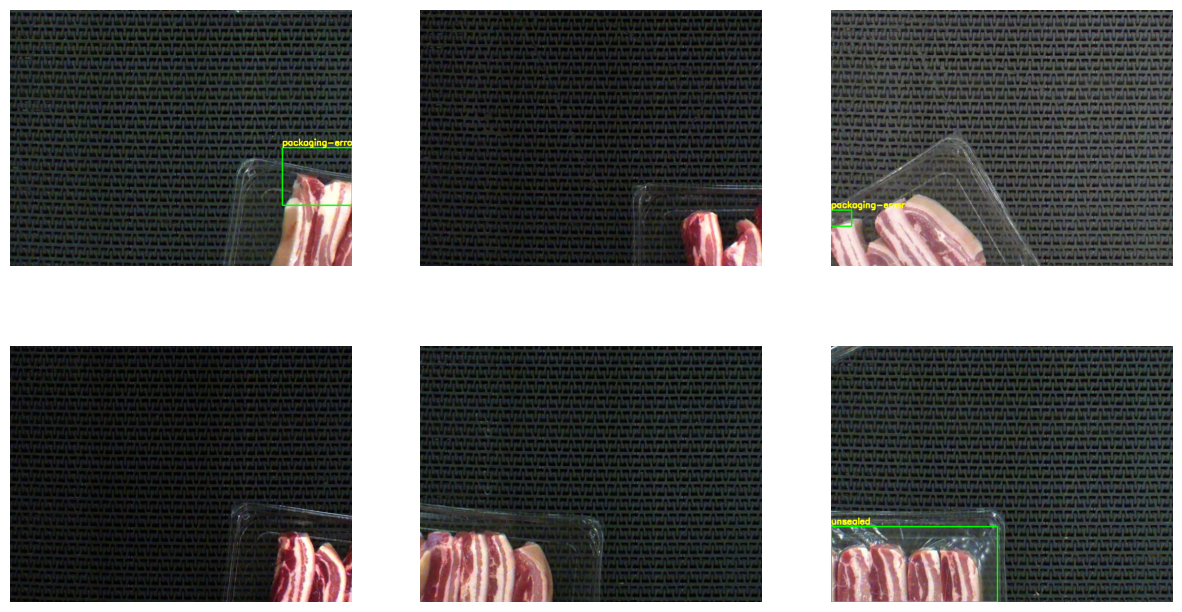

In [ ]:
def show(split='train', n=6, seed=0):
    random.seed(seed)
    files = random.sample(list_images(root, split), n)
    fig, axs = plt.subplots(2, 3, figsize=(15, 8))
    for ax, f in zip(axs.ravel(), files):
        img = cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        lab = root / split / 'labels' / (f.stem + '.txt')
        if lab.exists():
            for line in lab.read_text().splitlines():
                c, x, y, bw, bh = line.split()[:5]
                x, y, bw, bh = float(x)*w, float(y)*h, float(bw)*w, float(bh)*h
                p1, p2 = (int(x - bw/2), int(y - bh/2)), (int(x + bw/2), int(y + bh/2))
                cv2.rectangle(img, p1, p2, (0, 255, 0), 2)
                cv2.putText(img, names[int(c)], (p1[0], p1[1] - 5),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 0), 2)
        ax.imshow(img); ax.axis('off')
    plt.show()

show()

### 1.3 Leakage check and cleaning
Augmented copies share the original frame name before `.rf.`, so the same frame can sit in two splits and inflate scores. `remove_leakage` deletes train copies of any frame found in valid or test, and removes a valid/test shared frame from test. (Found originally: 8 frames shared by train/valid, 4 by train/test, 1 by valid/test.)

In [ ]:
print('Shared frames BEFORE:', {k: len(v) for k, v in overlaps(DATA).items()})
removed = remove_leakage(DATA)
print('Images removed:', removed)
print('Shared frames AFTER: ', {k: len(v) for k, v in overlaps(DATA).items()})
print({s: len(list_images(DATA, s)) for s in ['train', 'valid', 'test']})

Shared frames BEFORE: {'train&valid': 8, 'train&test': 4, 'valid&test': 1}
Images removed: {'train': 36, 'test': 1}
Shared frames AFTER:  {'train&valid': 0, 'train&test': 0, 'valid&test': 0}
{'train': 3313, 'valid': 120, 'test': 79}


### 1.4 Write the training data config
Uses my own YAML because Roboflow's relative paths are unreliable.

In [ ]:
DATA_YAML = '/content/my_data.yaml'
with open(DATA_YAML, 'w') as f:
    yaml.safe_dump({'path': DATA, 'train': 'train/images', 'val': 'valid/images',
                    'test': 'test/images', 'names': names}, f)
print(open(DATA_YAML).read())

names:
- loose-meat
- packaging-error
- twisted-meat
- unsealed
- wrinkle
path: /content/data
test: test/images
train: train/images
val: valid/images



## 2. Training
Three runs with identical settings except the variable under test, so the comparison is fair:

| Run | Model | imgsz | Question |
|---|---|---|---|
| `v8n_640` | YOLOv8n | 640 | Baseline |
| `v8s_640` | YOLOv8s | 640 | Does a bigger model buy accuracy, and what does it cost in speed? |
| `v8n_480` | YOLOv8n | 480 | How much does a smaller input hurt or speed things up? |

A 5-epoch smoke test (YOLOv8n, 640) ran first: about 33 s/epoch on the T4, val mAP50 0.30 after 5 epochs, inference about 9.8 ms/image. Weights and logs are saved to Drive so a disconnect cannot lose them.

### 2.1 Settings and helper
`train_run` skips a finished run (marked by a `DONE` file), resumes an interrupted one from `last.pt`, and otherwise starts fresh. Running from `/content` keeps downloaded weights out of the repo.

In [ ]:
%cd /content
from ultralytics import YOLO

RUNS = '/content/drive/MyDrive/mma3001/runs'
COMMON = dict(data=DATA_YAML, epochs=50, batch=16, seed=0,
              cache='disk', patience=15, project=RUNS)

def train_run(name, weights, imgsz):
    """Train one run unless it has already finished; resume if interrupted."""
    run_dir = Path(RUNS) / name
    done, last = run_dir / 'DONE', run_dir / 'weights' / 'last.pt'
    if done.exists():
        print(f'{name}: already finished, skipping')
        return
    if last.exists():
        print(f'{name}: resuming interrupted run')
        YOLO(str(last)).train(resume=True)
    else:
        YOLO(weights).train(imgsz=imgsz, name=name, **COMMON)
    done.write_text('finished')

/content


### 2.2 Run 1: YOLOv8n @ 640 (baseline)

In [ ]:
train_run('v8n_640', 'yolov8n.pt', 640)

v8n_640: already finished, skipping


### 2.3 Run 2: YOLOv8s @ 640

In [ ]:
train_run('v8s_640', 'yolov8s.pt', 640)

Ultralytics 8.4.185 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/my_data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v8s_640, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto

### 2.4 Run 3: YOLOv8n @ 480

In [ ]:
train_run('v8n_480', 'yolov8n.pt', 480)

Ultralytics 8.4.185 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/my_data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=480, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v8n_480, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto

## 3. Evaluation
The rules below were fixed before the test split was examined:
- The model was selected on **validation** mAP50-95 (`v8n_640`). The test split is used once, and all three runs are reported whichever scores highest on test.
- The tray-level confidence threshold is chosen on the validation split only.

| Step | Content |
|---|---|
| 3.1 | Test-set metrics for all three runs |
| 3.2 | Speed, size and FLOPs benchmark |
| 3.3 | Tray-level PASS/FAIL: threshold on validation, result on test |
| 3.4 | Failure analysis: missed trays and false alarms |
| 3.5 | Location check: is tray recall backed by detections on real defects? |
| 3.6 | Trays rejected only by wrong-place detections |
| 3.7 | Edge-position check (hypothesis rejected) |
| 3.8 | Single versus multiple defects |

### 3.1 Test-set evaluation (all three runs)
Each run's `best.pt` is evaluated once on the test split. `mAP50 (big 2)` averages `packaging-error` and `unsealed`, the only classes with enough boxes to score reliably.

In [ ]:
import os, pandas as pd
from ultralytics import YOLO

RESULTS = '/content/pork-rasher-inspection/results'
os.makedirs(RESULTS, exist_ok=True)
RUN_SIZES = {'v8n_640': 640, 'v8s_640': 640, 'v8n_480': 480}
BIG = ['packaging-error', 'unsealed']   # classes with enough boxes to score meaningfully

summary, per_class = [], []
for name, sz in RUN_SIZES.items():
    model = YOLO(f'{RUNS}/{name}/weights/best.pt')
    r = model.val(data=DATA_YAML, split='test', imgsz=sz, batch=16,
                  project=f'{RUNS}/eval', name=f'{name}_test', exist_ok=True, verbose=False)
    ap50 = {r.names[int(c)]: float(a) for c, a in zip(r.box.ap_class_index, r.box.ap50)}
    summary.append({'run': name, 'mAP50': r.box.map50, 'mAP50-95': r.box.map,
                    'precision': r.box.mp, 'recall': r.box.mr,
                    'mAP50 (big 2)': sum(ap50[c] for c in BIG) / len(BIG)})
    per_class.append({'run': name, **ap50})

summary = pd.DataFrame(summary).round(3)
per_class = pd.DataFrame(per_class).round(3)
display(summary); display(per_class)
summary.to_csv(f'{RESULTS}/test_summary.csv', index=False)
per_class.to_csv(f'{RESULTS}/test_per_class_map50.csv', index=False)

Ultralytics 8.4.185 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1579.9±926.3 MB/s, size: 66.0 KB)
val: Scanning /content/data/test/labels... 79 images, 11 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 79/79 2.2Kit/s 0.0s
val: New cache created: /content/data/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.1it/s 2.4s
                   all         79         79      0.473      0.511      0.534      0.234
Speed: 5.4ms preprocess, 5.7ms inference, 0.0ms loss, 3.4ms postprocess per image
Results saved to /content/drive/MyDrive/mma3001/runs/eval/v8n_640_test
Ultralytics 8.4.185 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,519 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, 

,run,mAP50,mAP50-95,precision,recall,mAP50 (big 2)
0,v8n_640,0.534,0.234,0.473,0.511,0.616
1,v8s_640,0.567,0.268,0.747,0.464,0.634
2,v8n_480,0.544,0.229,0.473,0.617,0.709


,run,loose-meat,packaging-error,twisted-meat,unsealed
0,v8n_640,0.863,0.421,0.041,0.811
1,v8s_640,0.753,0.440,0.245,0.829
2,v8n_480,0.665,0.565,0.092,0.853


### 3.2 Speed, size and FLOPs benchmark
All three models are timed in one session on the same test images: 30 warm-up predictions, then three passes, with the GPU synchronised around every call. Times include resize, inference and NMS, and exclude disk reading and camera capture.

In [ ]:
import time, cv2, torch, numpy as np
from ultralytics.utils.torch_utils import get_flops

test_imgs = [cv2.imread(str(p)) for p in sorted(list_images(DATA, 'test'))]

def benchmark(name, sz, warmup=30, repeats=3):
    path = f'{RUNS}/{name}/weights/best.pt'
    model = YOLO(path)
    run = lambda im: model.predict(im, imgsz=sz, conf=0.25, device=0, verbose=False)
    for i in range(warmup):                      # warm-up: GPU clocks, CUDA init
        run(test_imgs[i % len(test_imgs)])
    ms = []
    for _ in range(repeats):
        for im in test_imgs:
            torch.cuda.synchronize(); t0 = time.perf_counter()
            run(im)
            torch.cuda.synchronize(); ms.append((time.perf_counter() - t0) * 1000)
    ms = np.array(ms)
    try:
        gflops = get_flops(model.model, imgsz=sz)
    except Exception:
        gflops = float('nan')
    return {'run': name, 'imgsz': sz,
            'params_M': sum(p.numel() for p in model.model.parameters()) / 1e6,
            'GFLOPs': gflops, 'size_MB': os.path.getsize(path) / 1e6,
            'ms_mean': ms.mean(), 'ms_median': np.median(ms), 'ms_p95': np.percentile(ms, 95),
            'FPS': 1000 / ms.mean(), 'real_time_30FPS': 1000 / ms.mean() >= 30}

bench = pd.DataFrame([benchmark(n, s) for n, s in RUN_SIZES.items()]).round(2)
display(bench)
bench.to_csv(f'{RESULTS}/benchmark.csv', index=False)

,run,imgsz,params_M,GFLOPs,size_MB,ms_mean,ms_median,ms_p95,FPS,real_time_30FPS
0,v8n_640,640,3.14,8.75,6.50,8.64,8.46,10.18,115.70,True
1,v8s_640,640,11.14,28.65,22.51,13.04,13.05,13.85,76.67,True
2,v8n_480,480,3.14,4.92,6.48,7.95,7.81,9.27,125.80,True


### 3.3 Tray-level PASS/FAIL
#### 3.3a Write the tray inspector module
Written to `src/` so it can be imported, tested with pytest and documented with pdoc.

In [ ]:
%%writefile /content/pork-rasher-inspection/src/tray_inspector.py
"""Tray-level PASS/FAIL logic on top of a YOLO detector.

A tray FAILS if the detector finds at least one defect with confidence at or
above the threshold; otherwise it PASSES.
"""
import math
from pathlib import Path

import cv2

IMG_EXT = {".jpg", ".jpeg", ".png"}


def tray_verdict(confidences, threshold):
    """Return "FAIL" if any confidence >= threshold, else "PASS".

    Args:
        confidences: Iterable of detection confidences (0 to 1).
        threshold: Confidence threshold (0 to 1).

    Returns:
        "PASS" or "FAIL".
    """
    return "FAIL" if any(c >= threshold for c in confidences) else "PASS"


def wilson_interval(successes, n, z=1.96):
    """Wilson score confidence interval for a proportion (95% by default).

    Args:
        successes: Number of successes.
        n: Number of trials.
        z: Normal quantile (1.96 gives 95%).

    Returns:
        (low, high), or (nan, nan) if n is 0.
    """
    if n == 0:
        return (float("nan"), float("nan"))
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return (max(0.0, centre - half), min(1.0, centre + half))


def check_image(image_path):
    """Validate an input image path.

    Args:
        image_path: Path to a JPG/PNG image.

    Returns:
        The path as a Path object.

    Raises:
        FileNotFoundError: if the file does not exist.
        ValueError: if the extension is unsupported or the file is unreadable.
    """
    p = Path(image_path)
    if not p.is_file():
        raise FileNotFoundError(f"No such file: {p}")
    if p.suffix.lower() not in IMG_EXT:
        raise ValueError(f"Unsupported image type: {p.suffix}")
    if cv2.imread(str(p)) is None:
        raise ValueError(f"Unreadable image: {p}")
    return p


def inspect_tray(image_path, model, threshold=0.25, imgsz=640):
    """Detect defects in one tray image and return a PASS/FAIL verdict.

    Args:
        image_path: Path to a JPG/PNG tray image.
        model: A loaded ultralytics YOLO model.
        threshold: Confidence threshold in (0, 1].
        imgsz: Inference image size.

    Returns:
        Dict with "verdict" and "detections" (list of dicts with "class",
        "confidence", "box_xyxy").

    Raises:
        FileNotFoundError, ValueError: see check_image; also if threshold
            is outside (0, 1].
    """
    if not 0 < threshold <= 1:
        raise ValueError(f"threshold must be in (0, 1], got {threshold}")
    p = check_image(image_path)
    res = model.predict(str(p), conf=threshold, imgsz=imgsz, verbose=False)[0]
    dets = [{"class": res.names[int(b.cls)],
             "confidence": float(b.conf),
             "box_xyxy": [float(v) for v in b.xyxy[0]]} for b in res.boxes]
    return {"verdict": tray_verdict([d["confidence"] for d in dets], threshold),
            "detections": dets}

Writing /content/pork-rasher-inspection/src/tray_inspector.py


#### 3.3b Choose the threshold on validation, report once on test
Rules, fixed before any test result was examined:
- A tray is **defective** if its label file contains any box, and **good** if the file is empty.
- The confidence threshold is chosen on the **validation** split only, by maximising recall minus false-alarm rate (ties go to the lower threshold).
- The **test** split is reported once, with 95% Wilson confidence intervals, against an "always FAIL" baseline.

In [ ]:
import numpy as np, pandas as pd
sys.path.insert(0, '/content/pork-rasher-inspection/src')
from tray_inspector import wilson_interval

SEL, SEL_SZ = 'v8n_640', 640            # selected on validation mAP50-95
model = YOLO(f'{RUNS}/{SEL}/weights/best.pt')

def tray_table(split):
    """Max detection confidence per image, plus whether it has a labelled defect."""
    rows = []
    for img in sorted(list_images(DATA, split)):
        lab = Path(DATA) / split / 'labels' / (img.stem + '.txt')
        has_defect = lab.exists() and lab.read_text().strip() != ''
        r = model.predict(str(img), conf=0.001, imgsz=SEL_SZ, verbose=False)[0]
        rows.append((img.name, has_defect, float(r.boxes.conf.max()) if len(r.boxes) else 0.0))
    return pd.DataFrame(rows, columns=['image', 'has_defect', 'max_conf'])

def metrics(df, t):
    fail = df.max_conf >= t
    tp = int((fail & df.has_defect).sum());  fn = int((~fail & df.has_defect).sum())
    fp = int((fail & ~df.has_defect).sum()); tn = int((~fail & ~df.has_defect).sum())
    return dict(threshold=round(float(t), 2), TP=tp, FN=fn, FP=fp, TN=tn,
                recall=tp / (tp + fn), false_alarm=fp / (fp + tn))

val_df, test_df = tray_table('valid'), tray_table('test')

# 1) choose threshold on VALID only
sweep = pd.DataFrame([metrics(val_df, t) for t in np.arange(0.05, 0.96, 0.05)])
sweep['J'] = sweep.recall - sweep.false_alarm
best_t = float(sweep.loc[sweep.J.idxmax(), 'threshold'])
display(sweep.round(3))
print('Chosen threshold (from valid):', best_t)

# 2) report on TEST once, with 95% Wilson intervals
m = metrics(test_df, best_t)
rec_ci = wilson_interval(m['TP'], m['TP'] + m['FN'])
fa_ci = wilson_interval(m['FP'], m['FP'] + m['TN'])
n_def, n_good = m['TP'] + m['FN'], m['FP'] + m['TN']
print(f"Test trays: {n_def} defective, {n_good} good")
print(f"Recall (defects caught): {m['recall']:.3f}  95% CI [{rec_ci[0]:.3f}, {rec_ci[1]:.3f}]  ({m['TP']}/{n_def})")
print(f"False-alarm rate:        {m['false_alarm']:.3f}  95% CI [{fa_ci[0]:.3f}, {fa_ci[1]:.3f}]  ({m['FP']}/{n_good})")
print(f"Baseline 'always FAIL':  recall 1.000, false-alarm 1.000, accuracy {n_def/(n_def+n_good):.3f}")

sweep.to_csv(f'{RESULTS}/tray_threshold_sweep_valid.csv', index=False)
pd.DataFrame([{**m, 'recall_ci_low': rec_ci[0], 'recall_ci_high': rec_ci[1],
               'fa_ci_low': fa_ci[0], 'fa_ci_high': fa_ci[1]}]).to_csv(f'{RESULTS}/tray_test_result.csv', index=False)

,threshold,TP,FN,FP,TN,recall,false_alarm,J
0,0.05,104,2,5,9,0.981,0.357,0.624
1,0.10,104,2,3,11,0.981,0.214,0.767
2,0.15,103,3,3,11,0.972,0.214,0.757
3,0.20,103,3,3,11,0.972,0.214,0.757
4,0.25,101,5,3,11,0.953,0.214,0.739
5,0.30,100,6,3,11,0.943,0.214,0.729
6,0.35,97,9,2,12,0.915,0.143,0.772
7,0.40,92,14,2,12,0.868,0.143,0.725
8,0.45,92,14,2,12,0.868,0.143,0.725
9,0.50,86,20,2,12,0.811,0.143,0.668


Chosen threshold (from valid): 0.35
Test trays: 68 defective, 11 good
Recall (defects caught): 0.853  95% CI [0.750, 0.918]  (58/68)
False-alarm rate:        0.091  95% CI [0.016, 0.377]  (1/11)
Baseline 'always FAIL':  recall 1.000, false-alarm 1.000, accuracy 0.861


### 3.4 Failure analysis: missed trays and false alarms
Test trays that the selected model passes although they are defective (missed), or fails although they are good (false alarm), at the chosen threshold. Green = ground truth, red = predictions at confidence >= 0.10.

10 missed defective trays | 1 false alarm(s) at threshold 0.35
Ground-truth boxes inside missed trays: {'packaging-error': 3, 'loose-meat': 1, 'unsealed': 3, 'twisted-meat': 3}


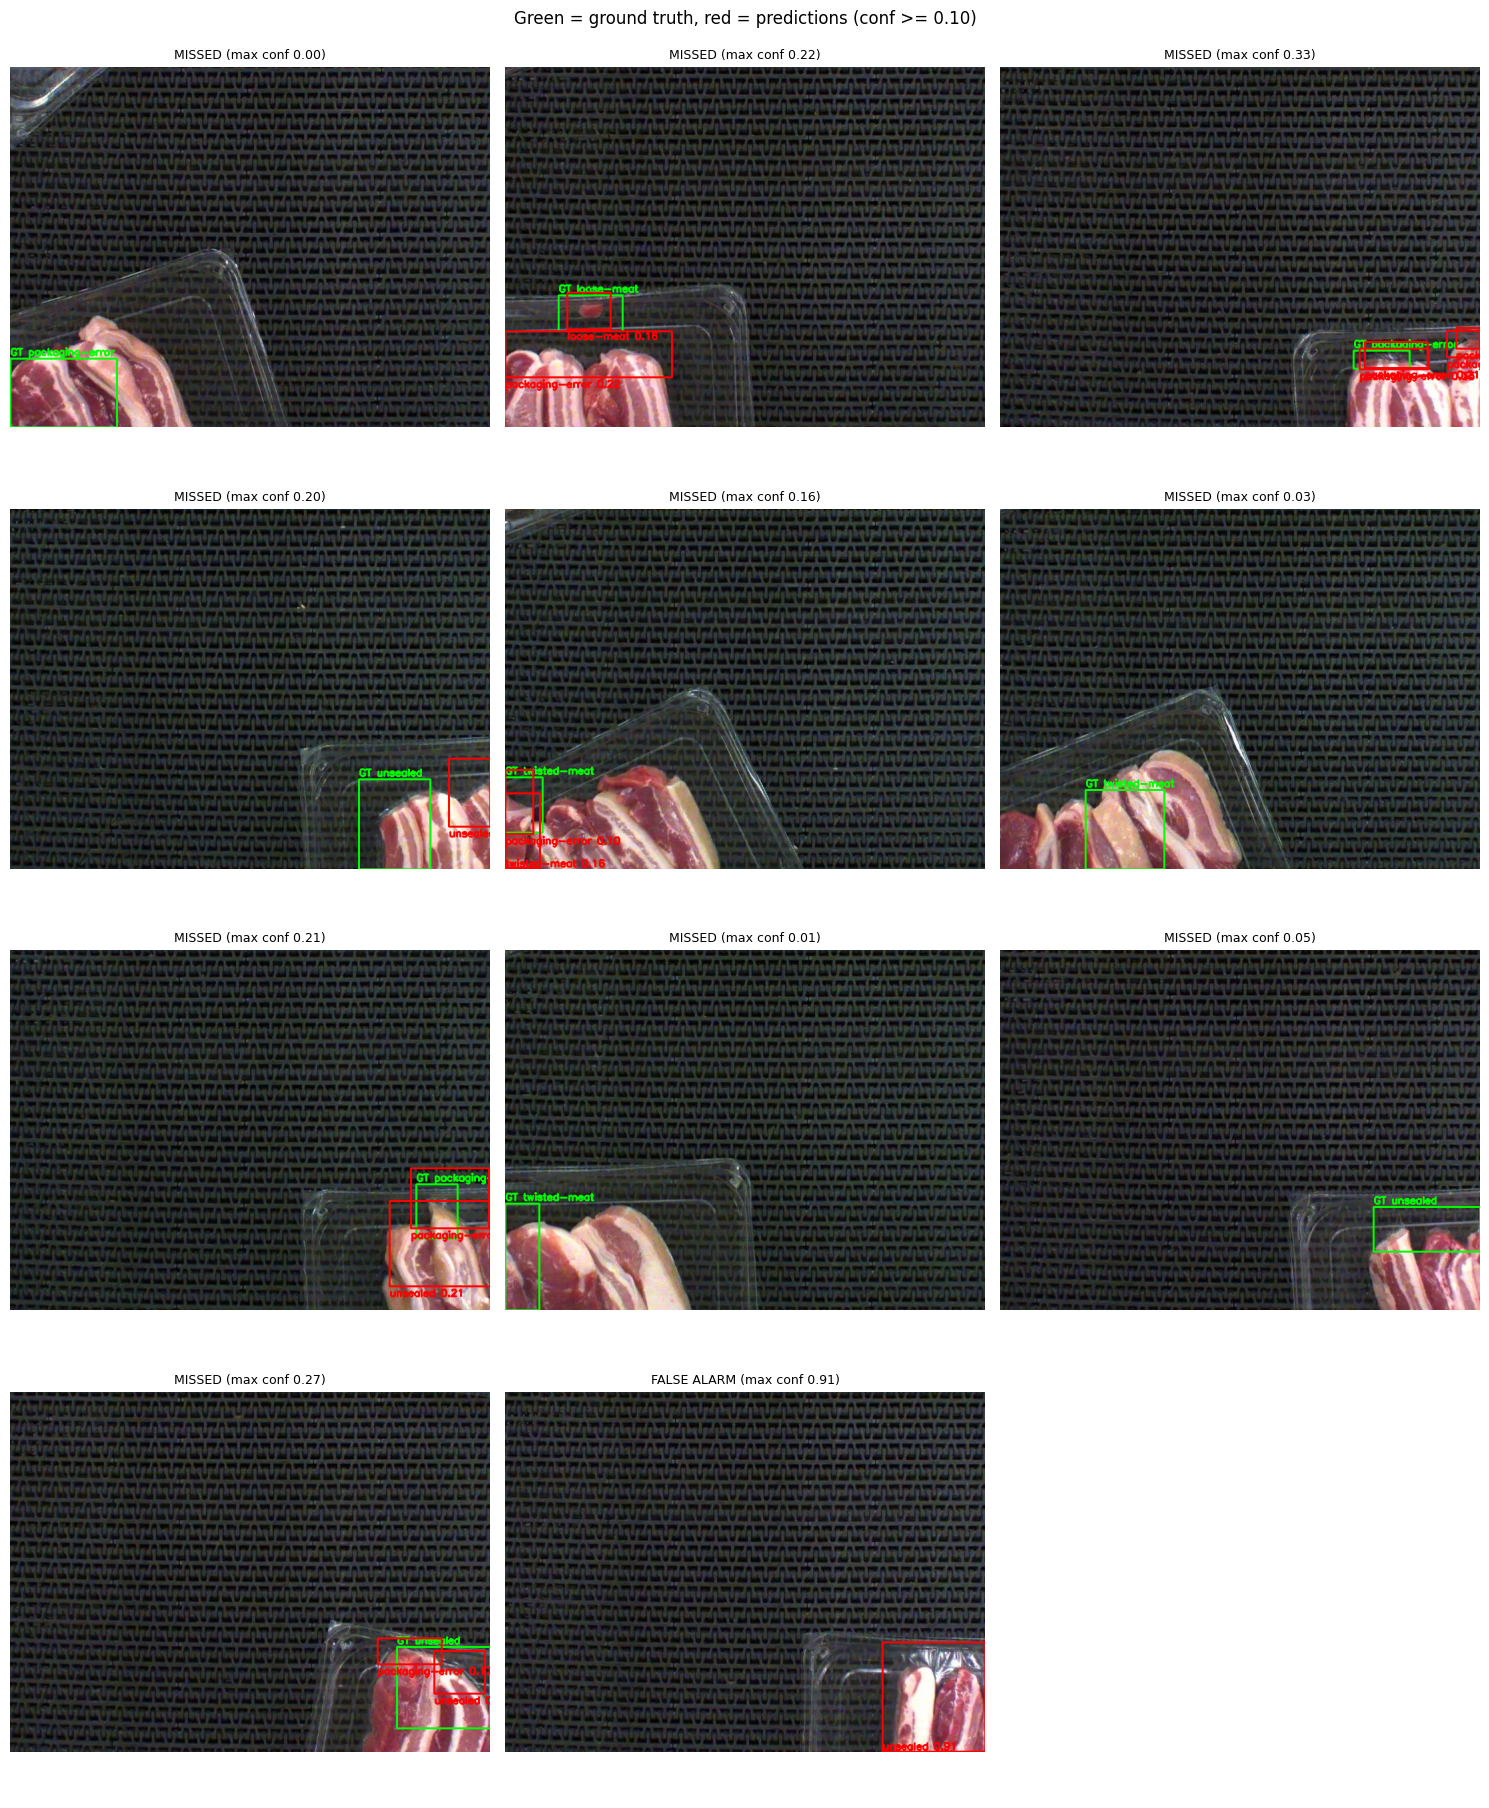

In [ ]:
import math
FONT = cv2.FONT_HERSHEY_SIMPLEX
t = best_t
test_df['fail'] = test_df.max_conf >= t
fn_df = test_df[test_df.has_defect & ~test_df.fail]      # defective trays we passed
fp_df = test_df[~test_df.has_defect & test_df.fail]      # good trays we failed
print(len(fn_df), 'missed defective trays |', len(fp_df), 'false alarm(s) at threshold', t)

# Which ground-truth classes sit in the missed trays?
missed = collections.Counter()
for name in fn_df.image:
    lab = Path(DATA) / 'test' / 'labels' / (Path(name).stem + '.txt')
    for line in lab.read_text().splitlines():
        if line.strip():
            missed[names[int(line.split()[0])]] += 1
print('Ground-truth boxes inside missed trays:', dict(missed))

def draw_case(ax, name, title, conf=0.10):
    p = Path(DATA) / 'test' / 'images' / name
    img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    for line in (Path(DATA) / 'test' / 'labels' / (p.stem + '.txt')).read_text().splitlines():
        if not line.strip():
            continue
        c, x, y, bw, bh = line.split()[:5]
        x, y, bw, bh = float(x)*w, float(y)*h, float(bw)*w, float(bh)*h
        x1, y1 = int(x - bw/2), int(y - bh/2)
        cv2.rectangle(img, (x1, y1), (int(x + bw/2), int(y + bh/2)), (0, 255, 0), 2)
        cv2.putText(img, 'GT ' + names[int(c)], (x1, max(y1 - 5, 12)), FONT, 0.5, (0, 255, 0), 2)
    r = model.predict(str(p), conf=conf, imgsz=SEL_SZ, verbose=False)[0]
    for b in r.boxes:
        x1, y1, x2, y2 = map(int, b.xyxy[0].tolist())
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
        cv2.putText(img, f'{r.names[int(b.cls)]} {float(b.conf):.2f}', (x1, min(y2 + 15, h - 4)), FONT, 0.5, (255, 0, 0), 2)
    ax.imshow(img); ax.set_title(title, fontsize=9); ax.axis('off')

cases = [(n, f'MISSED (max conf {c:.2f})') for n, c in zip(fn_df.image, fn_df.max_conf)] + \
        [(n, f'FALSE ALARM (max conf {c:.2f})') for n, c in zip(fp_df.image, fp_df.max_conf)]
cols = 3
rows = math.ceil(len(cases) / cols)
fig, axs = plt.subplots(rows, cols, figsize=(15, 4.6 * rows))
for ax in axs.ravel():
    ax.axis('off')
for ax, (n, title) in zip(axs.ravel(), cases):
    draw_case(ax, n, title)
plt.suptitle('Green = ground truth, red = predictions (conf >= 0.10)')
plt.tight_layout()
plt.savefig(f'{RESULTS}/failure_cases.png', dpi=130, bbox_inches='tight')
plt.show()

### 3.5 Location check: is tray recall backed by detections on real defects?
The tray rule ignores where a detection is. Here a defective tray only counts as truly detected if a flagged detection overlaps a labelled defect (class ignored).

#### IoU >= 0.5

In [ ]:
def iou(a, b):
    """IoU of two [x1, y1, x2, y2] boxes."""
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / union if union > 0 else 0.0

def gt_boxes(split, stem, w, h):
    """Ground-truth boxes for one image as (class_id, [x1, y1, x2, y2]) in pixels."""
    out = []
    for line in (Path(DATA) / split / 'labels' / (stem + '.txt')).read_text().splitlines():
        if line.strip():
            c, x, y, bw, bh = map(float, line.split()[:5])
            out.append((int(c), [(x - bw/2)*w, (y - bh/2)*h, (x + bw/2)*w, (y + bh/2)*h]))
    return out

rows = []
for name in test_df[test_df.has_defect].image:
    p = Path(DATA) / 'test' / 'images' / name
    r = model.predict(str(p), conf=best_t, imgsz=SEL_SZ, verbose=False)[0]
    h, w = r.orig_shape
    gts = gt_boxes('test', p.stem, w, h)
    preds = [b.xyxy[0].tolist() for b in r.boxes]
    rows.append((name, len(preds) > 0,
                 any(iou(pb, g[1]) >= 0.5 for pb in preds for g in gts)))
loc = pd.DataFrame(rows, columns=['image', 'flagged', 'located'])

n = len(loc)
k_flag, k_loc = int(loc.flagged.sum()), int(loc.located.sum())
lo, hi = wilson_interval(k_loc, n)
print(f'Defective trays: {n}')
print(f'Flagged FAIL (any detection >= {best_t}): {k_flag}  ({k_flag/n:.3f})')
print(f'  ...with a detection on a real defect (IoU >= 0.5): {k_loc}  ({k_loc/n:.3f}, 95% CI [{lo:.3f}, {hi:.3f}])')
print(f'  ...flagged only by detections in the wrong place: {k_flag - k_loc}')

Defective trays: 68
Flagged FAIL (any detection >= 0.35): 58  (0.853)
  ...with a detection on a real defect (IoU >= 0.5): 52  (0.765, 95% CI [0.651, 0.850])
  ...flagged only by detections in the wrong place: 6


#### Sensitivity: IoU >= 0.3

In [ ]:
def iou(a, b):
    """IoU of two [x1, y1, x2, y2] boxes."""
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / union if union > 0 else 0.0

def gt_boxes(split, stem, w, h):
    """Ground-truth boxes for one image as (class_id, [x1, y1, x2, y2]) in pixels."""
    out = []
    for line in (Path(DATA) / split / 'labels' / (stem + '.txt')).read_text().splitlines():
        if line.strip():
            c, x, y, bw, bh = map(float, line.split()[:5])
            out.append((int(c), [(x - bw/2)*w, (y - bh/2)*h, (x + bw/2)*w, (y + bh/2)*h]))
    return out

rows = []
for name in test_df[test_df.has_defect].image:
    p = Path(DATA) / 'test' / 'images' / name
    r = model.predict(str(p), conf=best_t, imgsz=SEL_SZ, verbose=False)[0]
    h, w = r.orig_shape
    gts = gt_boxes('test', p.stem, w, h)
    preds = [b.xyxy[0].tolist() for b in r.boxes]
    rows.append((name, len(preds) > 0,
                 any(iou(pb, g[1]) >= 0.3 for pb in preds for g in gts)))
loc = pd.DataFrame(rows, columns=['image', 'flagged', 'located'])

n = len(loc)
k_flag, k_loc = int(loc.flagged.sum()), int(loc.located.sum())
lo, hi = wilson_interval(k_loc, n)
print(f'Defective trays: {n}')
print(f'Flagged FAIL (any detection >= {best_t}): {k_flag}  ({k_flag/n:.3f})')
print(f'  ...with a detection on a real defect (IoU >= 0.3): {k_loc}  ({k_loc/n:.3f}, 95% CI [{lo:.3f}, {hi:.3f}])')
print(f'  ...flagged only by detections in the wrong place: {k_flag - k_loc}')

Defective trays: 68
Flagged FAIL (any detection >= 0.35): 58  (0.853)
  ...with a detection on a real defect (IoU >= 0.3): 54  (0.794, 95% CI [0.684, 0.873])
  ...flagged only by detections in the wrong place: 4


### 3.6 Trays rejected only by wrong-place detections
Defective trays that were rejected, but whose flagged detections do not overlap any labelled defect at IoU 0.3.

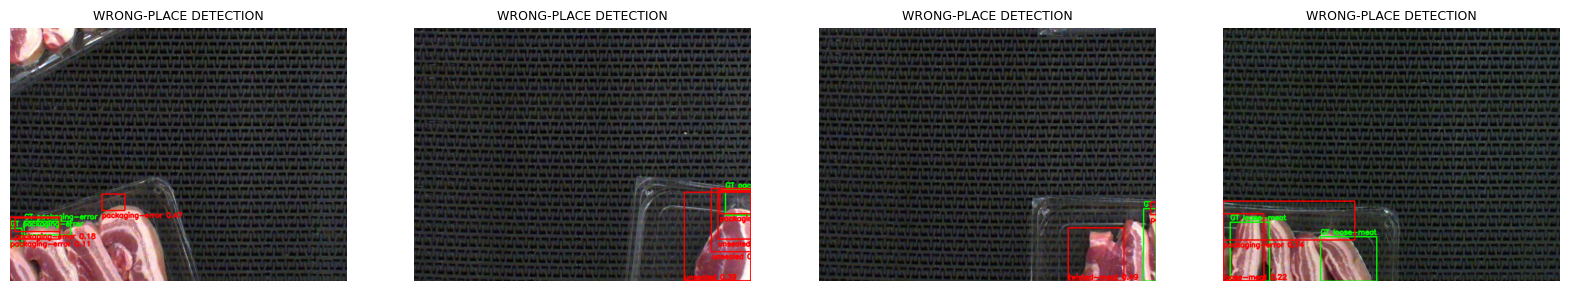

In [ ]:
wrong = loc[loc.flagged & ~loc.located].image.tolist()
fig, axs = plt.subplots(1, len(wrong), figsize=(5 * len(wrong), 4.6))
for ax, n in zip(np.atleast_1d(axs), wrong):
    draw_case(ax, n, 'WRONG-PLACE DETECTION')
plt.show()

### 3.7 Edge-position check (hypothesis rejected)
Failures looked as if they cluster near the image edge. This compares the share of boxes within 10% of an image edge in train, in all of test, and in the 14 failure trays. The failure trays are not more edge-heavy than the rest of test, so edge position does not explain the failures.

In [ ]:
def near_edge(lines, m=0.10):
    """True/False per box: does it come within a fraction m of any image edge?"""
    flags = []
    for l in lines:
        if l.strip():
            _, x, y, bw, bh = map(float, l.split()[:5])
            flags.append(x - bw/2 < m or x + bw/2 > 1 - m or y - bh/2 < m or y + bh/2 > 1 - m)
    return flags

def edge_share(split, stems=None):
    flags = []
    for f in (Path(DATA) / split / 'labels').glob('*.txt'):
        if stems is None or f.stem in stems:
            flags += near_edge(f.read_text().splitlines())
    return sum(flags), len(flags)

fail_stems = {Path(n).stem for n in fn_df.image} | {Path(n).stem for n in wrong}
for label, (k, n) in {'train, all boxes': edge_share('train'),
                      'test, all boxes': edge_share('test'),
                      'test, boxes in the 14 failure trays': edge_share('test', fail_stems)}.items():
    print(f'{label:38} {k:4d} / {n:4d} near an image edge ({k/n:.2f})')

train, all boxes                       2140 / 2887 near an image edge (0.74)
test, all boxes                          72 /   79 near an image edge (0.91)
test, boxes in the 14 failure trays      14 /   16 near an image edge (0.88)


### 3.8 Single versus multiple defects
Rejection rate for defective test trays with one labelled defect against trays with two or more, with Wilson 95% intervals. Only nine multi-defect trays exist, so the two groups cannot be separated statistically.

In [ ]:
d = test_df[test_df.has_defect].copy()
d['n_boxes'] = [sum(1 for l in (Path(DATA) / 'test' / 'labels' / (Path(n).stem + '.txt')).read_text().splitlines() if l.strip())
                for n in d.image]
d['group'] = np.where(d.n_boxes == 1, 'single defect', '2+ defects')
for g, sub in d.groupby('group'):
    k, n = int(sub.fail.sum()), len(sub)
    lo, hi = wilson_interval(k, n)
    print(f'{g:14} {k}/{n} rejected ({k/n:.2f}, 95% CI [{lo:.2f}, {hi:.2f}])')

2+ defects     9/9 rejected (1.00, 95% CI [0.70, 1.00])
single defect  49/59 rejected (0.83, 95% CI [0.72, 0.91])


## 4. Tests and documentation
The tests in `tests/` and the `src/` modules are already in the repo cloned in section 0, so nothing needs uploading. The tests use a fake model, so they check the logic around the detector and do not exercise the real model. This cell also writes `tests/report.html` and the pdoc HTML documentation in `docs/`.

In [ ]:
%cd /content/pork-rasher-inspection
!pip -q install pytest-html
!pytest tests -v --html=tests/report.html --self-contained-html
!pdoc src/clean_splits.py src/tray_inspector.py -o docs

/content/pork-rasher-inspection
============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
metadata: {'Python': '3.13.16', 'Platform': 'Linux-6.6.122+-x86_64-with-glibc2.39', 'Packages': {'pytest': '8.4.2', 'pluggy': '1.7.0'}, 'Plugins': {'metadata': '3.1.1', 'html': '4.2.0', 'typeguard': '4.6.0', 'anyio': '4.15.1', 'langsmith': '0.14.11', 'platformdirs': '4.13.5'}}
rootdir: /content/pork-rasher-inspection
plugins: metadata-3.1.1, html-4.2.0, typeguard-4.6.0, anyio-4.15.1, langsmith-0.14.11, platformdirs-4.13.5
collected 25 items                                                             

tests/test_clean_splits.py::test_frame_id_strips_roboflow_suffix PASSED  [  4%]
tests/test_clean_splits.py::test_list_images_ignores_cache_files PASSED  [  8%]
tests/test_clean_splits.py::test_overlaps_finds_shared_frames PASSED     [ 12%]
tests/test_clean_splits.py::test_re

## 5. Commit to GitHub
Save the notebook first (Ctrl+S). This cell copies the latest saved notebook from Drive into `notebooks/01_pipeline.ipynb`, stages only `notebooks/`, `src/`, `tests/`, `docs/`, `results/`, the README, LICENSE and `.gitignore`, refuses to continue if weights, caches, zips or files over 25 MB are staged, then commits and pushes. It also removes the stray `tests/files.zip` that an earlier commit picked up. If the push is rejected it asks for a fresh token.

In [ ]:
# 5. Commit the finished notebook and project files to GitHub.
# Save this notebook first (Ctrl+S) so the copy in Drive is current.
import glob, os, shutil, subprocess, time
from getpass import getpass

REPO = '/content/pork-rasher-inspection'
NB_DIR = '/content/drive/MyDrive/Colab Notebooks'
GITHUB_REPO = 'opat0009-wq/pork-rasher-inspection'
COMMIT_MESSAGE = 'Add completed pipeline notebook, results, tests and docs'

def git(args, check=True, quiet=False):
    """Run a git command inside the repo, print its output and return stdout."""
    r = subprocess.run(['git', *args], cwd=REPO, capture_output=True, text=True)
    out = (r.stdout + r.stderr).strip()
    if out and not quiet:
        print(out)
    if check and r.returncode != 0:
        raise RuntimeError(f'git {args[0]} failed (see the output above)')
    return r.stdout.strip()

# 1) Make sure the repo is cloned in this session (asks for a token only if it is not)
if not os.path.isdir(f'{REPO}/.git'):
    token = getpass('GitHub token: ')
    r = subprocess.run(['git', 'clone', f'https://{token}@github.com/{GITHUB_REPO}.git', REPO],
                       cwd='/content', capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError('git clone failed: ' + (r.stdout + r.stderr).replace(token, '***'))
git(['config', 'user.name', 'opat0009-wq'])
git(['config', 'user.email', 'opat0009@student.monash.edu'])

# 2) Copy the latest saved notebook into the repo
if not os.path.isdir(NB_DIR):
    raise FileNotFoundError('Drive is not mounted: run cell 0.1 first.')
cands = [p for p in glob.glob(f'{NB_DIR}/*.ipynb') if 'pipeline' in os.path.basename(p).lower()]
if not cands:
    raise FileNotFoundError(f'No notebook with "pipeline" in its name in {NB_DIR}')
latest = max(cands, key=os.path.getmtime)
print(f'Using {os.path.basename(latest)} (saved {(time.time() - os.path.getmtime(latest)) / 60:.0f} min ago)')
os.makedirs(f'{REPO}/notebooks', exist_ok=True)
shutil.copy(latest, f'{REPO}/notebooks/01_pipeline.ipynb')

# 3) Keep stray zip files out of the repo (an earlier commit included tests/files.zip)
for z in glob.glob(f'{REPO}/**/*.zip', recursive=True):
    git(['rm', '-f', '-q', '--cached', '--ignore-unmatch', os.path.relpath(z, REPO)], check=False)
    os.remove(z)
gi = f'{REPO}/.gitignore'
text = open(gi).read() if os.path.exists(gi) else ''
missing = [p for p in ['data/', 'runs/', '*.pt', 'weights/', '*.zip', '*.npy'] if p not in text.split()]
if missing:
    with open(gi, 'a') as f:
        f.write(('\n' if text and not text.endswith('\n') else '') + '\n'.join(missing) + '\n')

# 4) Stage only what belongs in the repo (never "git add .")
for item in ['notebooks', 'src', 'tests', 'docs', 'results', 'README.md', 'LICENSE', '.gitignore']:
    if os.path.exists(f'{REPO}/{item}'):
        git(['add', item])

# 5) Safety check: stop before committing if weights, caches, zips or huge files are staged
staged = git(['diff', '--cached', '--name-only', '--diff-filter=AM'], quiet=True).splitlines()
bad = [n for n in staged if n.lower().endswith(('.pt', '.npy', '.zip'))
       or os.path.getsize(f'{REPO}/{n}') > 25e6]
if bad:
    git(['reset', '-q'])
    raise RuntimeError(f'Not committed. Remove these files first: {bad}')
print(f'{len(staged)} files staged, none are weights, caches, zips or over 25 MB')

# 6) Commit and push
if subprocess.run(['git', 'diff', '--cached', '--quiet'], cwd=REPO).returncode != 0:
    git(['commit', '-m', COMMIT_MESSAGE])
else:
    print('Nothing new to commit.')
r = subprocess.run(['git', 'push'], cwd=REPO, capture_output=True, text=True)
print((r.stdout + r.stderr).strip())
if r.returncode != 0:
    print('\nPush failed, usually an expired token or one without write access.')
    token = getpass('Paste a fresh GitHub token (classic with "repo", or fine-grained with Contents: read and write): ')
    git(['remote', 'set-url', 'origin', f'https://{token}@github.com/{GITHUB_REPO}.git'])
    git(['push'])

print('\nLatest commit:')
git(['log', '-1', '--stat', '--oneline'])
git(['status', '-sb'])
print(f'\nCheck it on GitHub: https://github.com/{GITHUB_REPO}')